## Training a Classifier Using Quantum Embedding Kernels

In this example, a quantum computer is used to construct and train a kernel function for an SVM (Support Vector Machine), a machine learning algorithm. The trained quantum kernel is then used to perform classification.

This sample is designed to run on ABCI-Q. Specifically, it runs in the Covalent Jupyter Notebook environment launched through Open OnDemand. For detailed instructions on how to use the environment, please refer to the [Covalent Manual](https://g-quat-abciq.github.io/abciq-docs/ja/apps/covalent/) in the ABCI-Q User Guide.

This sample is based on the Covalent tutorial ["Training Quantum Embedding Kernels for Classification"](https://covalent.readthedocs.io/en/latest/tutorials/1_QuantumMachineLearning/quantum_embedding_kernel/source.html).

The implementation has been modified to use quri-parts-oqtopus.

In this sample, SVM training is performed only once. For more advanced implementations, such as evaluating and improving classifier performance through training optimization, please refer to the original tutorial.

### 1. Installation and Import of Required Libraries



In [ ]:
!pip install matplotlib
!pip install scikit-learn

In [2]:
import covalent as ct

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.inspection import DecisionBoundaryDisplay
from quri_parts.circuit import QuantumCircuit
from quri_parts.circuit.inverse import inverse_circuit
from quri_parts_oqtopus.backend import OqtopusConfig, OqtopusSamplingBackend


np.random.seed(2022)

### 2. Generating Dataset

A dataset for the SVM classification task in the following sections is generated here.

Using the `make_blobs` function from scikit-learn, we create a dataset with two features and two classes.

The `get_data` function arranges nine clusters in a matrix-like layout and generates a total of 18 sample data points, with two data points in each cluster.

The `split_train_test` function divides the dataset into training and test sets at a ratio of 80% and 20%, respectively.

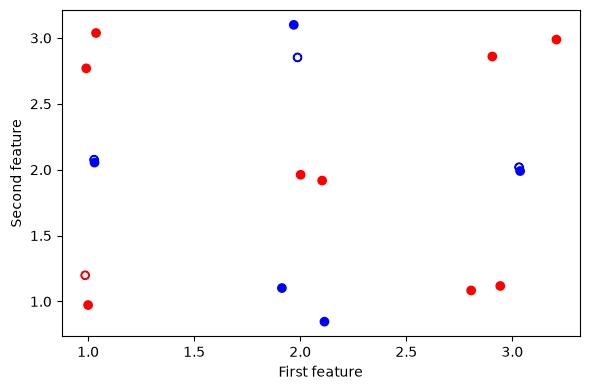

In [3]:
@ct.electron
def get_data(n_samples=18):
    centers = [(1, 1), (1, 2), (1, 3), (2, 1), (2, 2), (2, 3), (3, 1), (3, 2), (3, 3)]
    X, y = make_blobs(
        n_samples=n_samples, n_features=2, centers=centers, cluster_std=0.1, shuffle=False
    )
    # rescale labels to be -1, 1
    mapping = {0: -1, 1: 1, 2: -1, 3: 1, 4: -1, 5: 1, 6: -1, 7: 1, 8: -1}
    y = np.array([mapping[i] for i in y])
    X = X.astype(np.float32)
    y = y.astype(int)
    return X, y


@ct.electron
def split_train_test_data(X, y, test_size=0.2):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=3)
    return X_train, X_test, y_train, y_test

X, y = get_data()
X_train, X_test, y_train, y_test = split_train_test_data(X, y)

# 生成したデータセットをグラフにプロットする
cm = plt.cm.RdBu
cm_bright = ListedColormap(["#FF0000", "#0000FF"])
fig, ax = plt.subplots(1, 1, figsize=(6, 4), facecolor="w")
ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=cm_bright)
ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test, marker="$\u25EF$", cmap=cm_bright)
ax.set_xlabel("First feature")
ax.set_ylabel("Second feature")
plt.tight_layout()
plt.show()

### 3.　Creating a Quantum Kernel

A parameterized quantum circuit (ansatz) with repeated layers is designed and used to construct a quantum embedding kernel.

In each layer, the two input features are embedded into five qubits using the rotation angles of quantum gates.

For quantum kernel execution, the quantum circuits are run using quri-parts-oqtopus.

In [4]:
def add_crz(circuit: QuantumCircuit, control: int, target: int, theta: float):
    """
    CRZ(theta) を CNOT と RZ に分解

    CRZ(theta)
      = RZ(theta/2)
        CX
        RZ(-theta/2)
        CX
    """
    circuit.add_RZ_gate(target, theta / 2)
    circuit.add_CNOT_gate(control, target)
    circuit.add_RZ_gate(target, -theta / 2)
    circuit.add_CNOT_gate(control, target)

@ct.electron
def layer(x, params, n_qubits, i0=0, inc=1):
    circuit = QuantumCircuit(n_qubits)

    i = i0

    # Hadamard + RZ(x) + RY(param)
    for q in range(n_qubits):
        circuit.add_H_gate(q)
        circuit.add_RZ_gate(q, x[i % len(x)])
        circuit.add_RY_gate(q, params[0][q])
        i += inc

    # Ring CRZ
    for q in range(n_qubits):
        add_crz(
            circuit,
            control=q,
            target=(q + 1) % n_qubits,
            theta=params[1][q],
        )

    return circuit


@ct.electron
def ansatz(x, params):
    n_layers = params.shape[0]
    n_qubits = params.shape[2]
    circuit = QuantumCircuit(n_qubits)
    for j in range(n_layers):
        sub = layer(
            x,
            params[j],
            n_qubits,
            i0=j * n_qubits
        )
        circuit.extend(sub)

    return circuit

@ct.electron
def kernel_circuit(params):
    backend = OqtopusSamplingBackend(OqtopusConfig.from_file("oqtopus-dev"))

    def circuit(x1, x2, params):
        circuit1 = ansatz(x1, params)
        circuit2 = ansatz(x2, params)
        total = circuit1 + inverse_circuit(circuit2)

        shots = 1000
        job = backend.sample(
            total,
            device_id="qiskit_sim",
            shots=shots,
        )
        counts = job.result().counts
        print(f"x1={x1},x2={x2}: {counts}")
        n_states = 2 ** total.qubit_count
        probs = np.zeros(n_states)

        for state, count in counts.items():
            probs[state] = count / shots

        return probs

    return circuit

@ct.electron
def kernel(x1, x2, params):
    return kernel_circuit(params)(x1, x2, params)[0]

### 4. Building the SVM Training Program

A Support Vector Machine (SVM) classifier is constructed using the quantum kernel.

In the `svm` function, the kernel matrix (`kernel_matrix`) for the entire dataset is provided to SVC from scikit-learn. Each element of the `kernel_matrix` is obtained by executing the quantum kernel.

Finally, in the workflow `init_qsvm`, a quantum circuit is built using randomly generated quantum features. The SVM is trained only once, and its classification performance is evaluated. The function returns both the training accuracy and the test accuracy.

In [5]:
def kernel_matrix(X1, X2, params):
    K = np.zeros((len(X1), len(X2)))
    for i in range(len(X1)):
        for j in range(len(X2)):
            K[i, j] = kernel(
                X1[i],
                X2[j],
                params
            )

    return K

@ct.electron
def init_params(num_qubits, num_layers):
    return np.random.uniform(0, 2*np.pi, (num_layers, 2, num_qubits))


@ct.electron
def svm(X, y, params):
    svm = SVC(kernel=lambda x1, x2: kernel_matrix(x1, x2, params))
    svm.fit(X, y)
    return svm

@ct.electron
def calc_accuracy(classifier, X, y_true):
    return 1 - np.count_nonzero(classifier.predict(X) - y_true) / len(y_true)

@ct.lattice
def init_qsvm(n_samples=18, num_wires=5, num_layers=3):
    X, y = get_data(n_samples)
    X_train, X_test, y_train, y_test = split_train_test_data(X, y)
    params = init_params(num_wires, num_layers)
    classifier = svm(X_train, y_train, params)
    train_acc = calc_accuracy(classifier=classifier, X=X_train, y_true=y_train)
    test_acc = calc_accuracy(classifier=classifier, X=X_test, y_true=y_test)
    return classifier, X_train, y_train, X_test, y_test, train_acc, test_acc

### 5. Executing the Covalent Workflow and Retrieving Results

The workflow is executed on the Covalent server using `dispatch`. After the workflow has completed, the results are retrieved and the training and test accuracies are displayed.

In [6]:
dispatch_id = ct.dispatch(init_qsvm)(18, 5, 3)
result = ct.get_result(dispatch_id=dispatch_id, wait=True)
qsvm, X_train, y_train, X_test, y_test, train_acc, test_acc = result.result

In [7]:
print(f"Train accuracy: {train_acc}")
print(f"Test accuracy: {test_acc}")

Train accuracy: 0.8571428571428572
Test accuracy: 0.25
